<a href="https://colab.research.google.com/github/SanjeetKumarr/chai-cafe-analysis/blob/main/Chai_Cafe_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
ist i am going to import dataset

In [ ]:
import pandas as pd
df = pd.read_csv("/content/chai_cafe_orders.csv")

now i am going to see shape and type of dataset means shape means how many row and column are there and type means column type.

In [ ]:
df.shape

(304, 10)

In [ ]:
df.dtypes

,0
Order_ID,object
Order_Date,object
Item,object
Category,object
Quantity,int64
Unit_Price,int64
Branch,object
Payment_Mode,object
Customer_Age,int64
Rating,float64


now i know type of order date are wrong it must be in date format so now i am going to change it. by using to_datetime function.

In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

now i going to again check type of order date

In [ ]:
df['Order_Date'].dtype

dtype('<M8[ns]')

now i am going to change duration of this data set by calculating min andd max of orrder date

In [ ]:
df['Order_Date'].min()

Timestamp('2026-09-01 00:00:00')

In [ ]:
df['Order_Date'].max()

Timestamp('2026-09-30 00:00:00')

now i am going to cleaning data where 1st step of cleaning data is to know how many cell are blank in each column for this we use it.

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Item,0
Category,0
Quantity,0
Unit_Price,0
Branch,0
Payment_Mode,6
Customer_Age,0
Rating,18


now i am going to see these blank weightage on  this dataste

In [ ]:
df.isnull().mean()*100

,0
Order_ID,0.000000
Order_Date,0.000000
Item,0.000000
Category,0.000000
Quantity,0.000000
Unit_Price,0.000000
Branch,0.000000
Payment_Mode,1.973684
Customer_Age,0.000000
Rating,5.921053


now i am going to check why these cells are blank

In [ ]:
df[df['Payment_Mode'].isnull()]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
15,O1015,2026-09-20,Cutting Chai,Beverage,2,15,Andheri,NaN,37,4.0
67,O1067,2026-09-26,Cutting Chai,Beverage,2,15,Powai,NaN,46,4.0
154,O1154,2026-09-17,Masala Chai,Beverage,1,30,Andheri,NaN,59,5.0
162,O1162,2026-09-29,Cutting Chai,Beverage,1,15,Bandra,NaN,45,5.0
255,O1255,2026-09-26,Bun Maska,Snack,3,35,Andheri,NaN,41,4.0
259,O1259,2026-09-25,Vada Pav,Snack,2,25,Andheri,NaN,23,4.0


In [ ]:
df[df['Rating'].isnull()]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
6,O1006,2026-09-10,Bun Maska,Snack,2,35,Powai,UPI,32,NaN
34,O1034,2026-09-06,Filter Coffee,Beverage,2,60,Bandra,Cash,36,NaN
39,O1039,2026-09-29,Samosa,Snack,3,20,Powai,UPI,19,NaN
66,O1066,2026-09-16,Vada Pav,Snack,3,25,Powai,Card,29,NaN
73,O1073,2026-09-03,Cutting Chai,Beverage,2,15,Andheri,Card,25,NaN
75,O1075,2026-09-22,Cutting Chai,Beverage,1,15,Bandra,Cash,35,NaN
78,O1078,2026-09-16,Vada Pav,Snack,2,25,Bandra,UPI,20,NaN
79,O1079,2026-09-29,Bun Maska,Snack,3,35,Bandra,UPI,22,NaN
118,O1118,2026-09-08,Cold Coffee,Beverage,1,120,Andheri,UPI,23,NaN
119,O1119,2026-09-18,Vada Pav,Snack,1,25,Powai,UPI,59,NaN


now i am going to fill both of them blank, i fill payment method with missing or unknow because we do not guess what will be there payment mode then in rating blank , i also leave blank because there is three reason if i select mean then there blank will be fill with 3.7 something like means float that will be not good idea beacuse rating should be integer ad

In [ ]:
# Option A: khaali ko ek label se bharo
df['Payment_Mode'] = df['Payment_Mode'].fillna('Unknown')

In [ ]:
df['Payment_Mode'].value_counts()

,count
Payment_Mode,
UPI,165
Cash,82
Card,51
Unknown,6


now i had filled blank cell, now i am going to check duplicate value , this is second step of cleaning.

In [ ]:
df.duplicated().sum()


np.int64(4)

In [ ]:
df[df.duplicated(keep=False)].sort_values('Order_ID')

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
10,O1010,2026-09-26,Cold Coffee,Beverage,4,120,Andheri,Cash,39,5.0
300,O1010,2026-09-26,Cold Coffee,Beverage,4,120,Andheri,Cash,39,5.0
50,O1050,2026-09-15,Cutting Chai,Beverage,1,15,Andheri,UPI,53,4.0
301,O1050,2026-09-15,Cutting Chai,Beverage,1,15,Andheri,UPI,53,4.0
120,O1120,2026-09-05,Vada Pav,Snack,1,25,Andheri,Card,36,2.0
302,O1120,2026-09-05,Vada Pav,Snack,1,25,Andheri,Card,36,2.0
200,O1200,2026-09-01,Bun Maska,Snack,2,35,Andheri,UPI,54,3.0
303,O1200,2026-09-01,Bun Maska,Snack,2,35,Andheri,UPI,54,3.0


now i am going to remove duplicate value

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(300, 10)

In [ ]:
df.select_dtypes(include='object').columns

Index(['Order_ID', 'Item', 'Category', 'Branch', 'Payment_Mode'], dtype='object')

now i am going to check every text mmeans object column one by one where how many charcter are there.

In [ ]:
df['Branch'].value_counts()

,count
Branch,
Bandra,120
Andheri,95
Powai,73
andheri,3
POWAI,2
Bandra,2
ANDHERI,1
bandra,1
BANDRA,1


In [ ]:
df['Branch'] = df['Branch'].str.strip().str.title()

In [ ]:
df['Branch'].value_counts()

,count
Branch,
Bandra,124
Andheri,99
Powai,77


In [ ]:
df['Category'].value_counts()

,count
Category,
Beverage,161
Snack,108
Dessert,31


In [ ]:
df['Item'].value_counts()

,count
Item,
Masala Chai,66
Cutting Chai,44
Vada Pav,31
Bun Maska,29
Samosa,29
Cold Coffee,26
Filter Coffee,25
Sandwich,19
Brownie,19


In [ ]:
df['Payment_Mode'].value_counts()

,count
Payment_Mode,
UPI,163
Cash,81
Card,50
Unknown,6


Your checklist so far covers types, missing values, duplicates and text spelling. The last check is value ranges: whether the numbers themselves make sense. A column can have the right type, no blanks and no duplicates, and still contain a value that can’t be true.

In [ ]:
df.describe()

,Order_Date,Quantity,Unit_Price,Customer_Age,Rating
count,300,300.000000,300.000000,300.000000,282.000000
mean,2026-09-15 22:09:36,2.693333,58.766667,38.576667,3.638298
min,2026-09-01 00:00:00,-2.000000,15.000000,5.000000,1.000000
25%,2026-09-08 00:00:00,2.000000,25.000000,27.000000,3.000000
50%,2026-09-17 00:00:00,3.000000,30.000000,37.000000,4.000000
75%,2026-09-24 00:00:00,3.000000,80.000000,50.000000,4.750000
max,2026-09-30 00:00:00,60.000000,3000.000000,250.000000,5.000000
std,NaN,3.497628,174.539467,17.669129,1.152294


now i had checked each numerical column there are some error, now i am going to see details about those row one by one.

In [ ]:
df[df['Quantity'] < 0]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
203,O1203,2026-09-28,Masala Chai,Beverage,-2,30,Andheri,Cash,41,4.0


In [ ]:
df[df['Quantity'] > 10]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
142,O1142,2026-09-20,Brownie,Dessert,60,80,Powai,Cash,58,5.0


In [ ]:
df['Quantity'].sort_values().tail(5)

,Quantity
269,4
20,4
297,4
298,4
142,60


In [ ]:
df[df['Unit_Price'] > 200]


,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
260,O1260,2026-09-30,Masala Chai,Beverage,3,3000,Andheri,UPI,35,4.0


In [ ]:
df.groupby('Item')['Unit_Price'].agg(['min', 'max'])

,min,max
Item,,
Brownie,80,80
Bun Maska,35,35
Cheesecake,150,150
Cold Coffee,120,120
Cutting Chai,15,15
Filter Coffee,60,60
Masala Chai,30,3000
Samosa,20,20
Sandwich,90,90


In [ ]:
df[df['Customer_Age'] > 100]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
17,O1017,2026-09-08,Masala Chai,Beverage,4,30,Bandra,UPI,250,3.0


In [ ]:
df[df['Customer_Age'] < 10]

,Order_ID,Order_Date,Item,Category,Quantity,Unit_Price,Branch,Payment_Mode,Customer_Age,Rating
88,O1088,2026-09-14,Masala Chai,Beverage,1,30,Powai,UPI,5,2.0


now i am going to fix every numerical column one by one.

In [ ]:
# Price: correct to the known menu price
df.loc[df['Unit_Price'] > 500, 'Unit_Price'] = 30

In [ ]:
# Quantity: impossible or unsupported, so set to missing
import numpy as np

df.loc[(df['Quantity'] < 0) | (df['Quantity'] > 10), 'Quantity'] = np.nan


In [ ]:
df['Quantity'].dtype

dtype('float64')

In [ ]:
df['Quantity'].unique()

array([ 1.,  4.,  2.,  3., nan])

In [ ]:
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')

In [ ]:
df.dtypes

,0
Order_ID,object
Order_Date,datetime64[ns]
Item,object
Category,object
Quantity,float64
Unit_Price,int64
Branch,object
Payment_Mode,object
Customer_Age,int64
Rating,float64


In [ ]:
# Age: impossible, set to missing
df.loc[df['Customer_Age'] > 100, 'Customer_Age'] = np.nan

In [ ]:
df.describe()

,Order_Date,Quantity,Unit_Price,Customer_Age,Rating
count,300,298.000000,300.000000,299.000000,282.000000
mean,2026-09-15 22:09:36,2.516779,48.866667,37.869565,3.638298
min,2026-09-01 00:00:00,1.000000,15.000000,5.000000,1.000000
25%,2026-09-08 00:00:00,2.000000,25.000000,27.000000,3.000000
50%,2026-09-17 00:00:00,3.000000,30.000000,37.000000,4.000000
75%,2026-09-24 00:00:00,3.000000,80.000000,50.000000,4.750000
max,2026-09-30 00:00:00,4.000000,150.000000,59.000000,5.000000
std,NaN,1.073739,37.892414,12.757142,1.152294


now i am going to solve question one by one

1st question is After creating Revenue, how many blank values does it have, and why? Does one row match when you check it by hand?

In [ ]:
df['Revenue'] = df['Quantity'] * df['Unit_Price']

In [ ]:
df[['Item', 'Quantity', 'Unit_Price','Revenue']].head()

,Item,Quantity,Unit_Price,Revenue
0,Bun Maska,1.0,35,35.0
1,Cold Coffee,1.0,120,120.0
2,Sandwich,1.0,90,90.0
3,Samosa,4.0,20,80.0
4,Masala Chai,2.0,30,60.0


In [ ]:
df['Revenue'].isnull().sum()


np.int64(2)

In [ ]:
now i am going to answer 2nd questioon What is the total revenue for the month?

Object `month` not found.


In [ ]:
df['Revenue'].sum()

np.float64(37215.0)

how many orders that total is based on:

In [ ]:
df['Revenue'].count()

np.int64(298)

In [ ]:
df['Quantity'].count()

np.int64(298)

now i am going to answer this question
Which branch earns the most revenue?

In [ ]:
df.groupby('Branch')['Revenue'].sum().sort_values(ascending=False)

,Revenue
Branch,
Bandra,16400.0
Powai,10415.0
Andheri,10400.0


next question-Explain why Powai beats Andheri

In [ ]:
df['Branch'].value_counts()

,count
Branch,
Bandra,124
Andheri,99
Powai,77


In [ ]:
df.groupby('Branch')['Revenue'].mean()

,Revenue
Branch,
Andheri,106.122449
Bandra,132.258065
Powai,137.039474


next question-Which item earns the most revenue, and which earns the least?

In [ ]:
df.groupby('Item')['Revenue'].sum().sort_values()

,Revenue
Item,
Cutting Chai,1455.0
Samosa,1620.0
Vada Pav,2075.0
Bun Maska,2275.0
Filter Coffee,3360.0
Brownie,3840.0
Sandwich,4320.0
Cheesecake,4650.0
Masala Chai,5100.0


In [ ]:

df.groupby('Item')['Revenue'].sum().sum()

np.float64(37215.0)

next question- Which category (Beverage, Snack, Dessert) brings in the most money?

In [ ]:
df.groupby('Category')['Revenue'].sum().sort_values()

,Revenue
Category,
Dessert,8490.0
Snack,10290.0
Beverage,18435.0


next question-Which item sells the most by quantity, and is it the same as the top earner?

In [ ]:
df.groupby('Item')[['Quantity','Revenue']].sum().sort_values('Quantity')

,Quantity,Revenue
Item,,
Cheesecake,31.0,4650.0
Brownie,48.0,3840.0
Sandwich,48.0,4320.0
Filter Coffee,56.0,3360.0
Bun Maska,65.0,2275.0
Cold Coffee,71.0,8520.0
Samosa,81.0,1620.0
Vada Pav,83.0,2075.0
Cutting Chai,97.0,1455.0


next question-Which payment mode is the most popular, and is it the same in every branch?

In [ ]:
df['Payment_Mode'].value_counts()

,count
Payment_Mode,
UPI,163
Cash,81
Card,50
Unknown,6


In [ ]:
df.groupby(['Branch', 'Payment_Mode']).size()

Branch   Payment_Mode
Andheri  Card            14
         Cash            27
         UPI             54
         Unknown          4
Bandra   Card            20
         Cash            37
         UPI             66
         Unknown          1
Powai    Card            16
         Cash            17
         UPI             43
         Unknown          1
dtype: int64

In [ ]:
pd.crosstab(df['Branch'], df['Payment_Mode'])

Payment_Mode,Card,Cash,UPI,Unknown
Branch,,,,
Andheri,14,27,54,4
Bandra,20,37,66,1
Powai,16,17,43,1


In [ ]:
pd.crosstab(df['Branch'], df['Payment_Mode'], normalize='index')

Payment_Mode,Card,Cash,UPI,Unknown
Branch,,,,
Andheri,0.141414,0.272727,0.545455,0.040404
Bandra,0.161290,0.298387,0.532258,0.008065
Powai,0.207792,0.220779,0.558442,0.012987


In [ ]:
next question-What is the average customer age, and do older and younger customers prefer different categories?

Object `categories` not found.


In [ ]:
df['Customer_Age'].mean()

np.float64(37.869565217391305)

In [ ]:
df.groupby('Category')['Customer_Age'].mean()

,Customer_Age
Category,
Beverage,38.762500
Dessert,38.161290
Snack,36.462963


In [ ]:
df.groupby('Category')['Customer_Age'].agg(['mean', 'count'])

,mean,count
Category,,
Beverage,38.762500,160
Dessert,38.161290,31
Snack,36.462963,108


Question 10: What is the average rating overall and by branch?

In [ ]:
df['Rating'].mean()

np.float64(3.6382978723404253)

In [ ]:
df.groupby('Branch')['Rating'].agg(['mean', 'count'])

,mean,count
Branch,,
Andheri,3.691489,94
Bandra,3.635593,118
Powai,3.571429,70


Question 11: Which day of the month has the highest revenue? Is there a weekday or weekend pattern?

In [ ]:
daily = df.groupby('Order_Date')['Revenue'].sum()
daily.sort_values(ascending=False).head(5)

,Revenue
Order_Date,
2026-09-14,2355.0
2026-09-24,1880.0
2026-09-26,1850.0
2026-09-03,1825.0
2026-09-16,1800.0


In [ ]:
df['Weekday'] = df['Order_Date'].dt.day_name()
df.groupby('Weekday')['Revenue'].sum()

,Revenue
Weekday,
Friday,3820.0
Monday,4795.0
Saturday,6050.0
Sunday,3810.0
Thursday,6250.0
Tuesday,6015.0
Wednesday,6475.0


In [ ]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df.groupby('Weekday')['Revenue'].sum().reindex(order)

,Revenue
Weekday,
Monday,4795.0
Tuesday,6015.0
Wednesday,6475.0
Thursday,6250.0
Friday,3820.0
Saturday,6050.0
Sunday,3810.0


In [ ]:
daily = df.groupby('Order_Date')['Revenue'].sum().reset_index()
daily['Weekday'] = daily['Order_Date'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily.groupby('Weekday')['Revenue'].mean().reindex(order)

,Revenue
Weekday,
Monday,1198.75
Tuesday,1203.00
Wednesday,1295.00
Thursday,1562.50
Friday,955.00
Saturday,1512.50
Sunday,952.50


now i am going to make chart

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
rev = df.groupby('Branch')['Revenue'].sum().sort_values(ascending=False)

Text(0.5, 0, 'Branch')

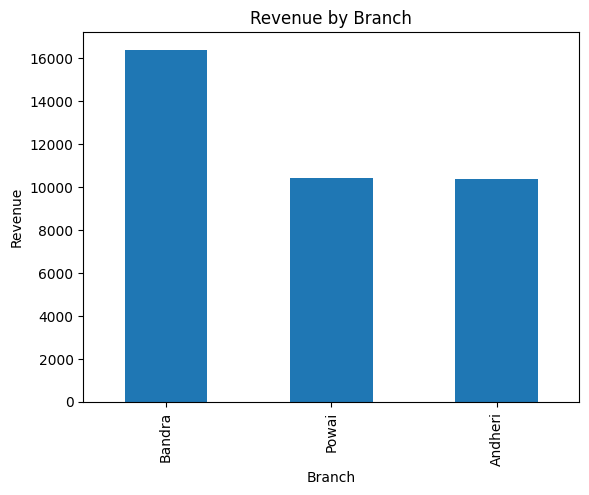

In [ ]:
rev.plot(kind='bar')
plt.title('Revenue by Branch')
plt.ylabel('Revenue')
plt.xlabel('Branch')


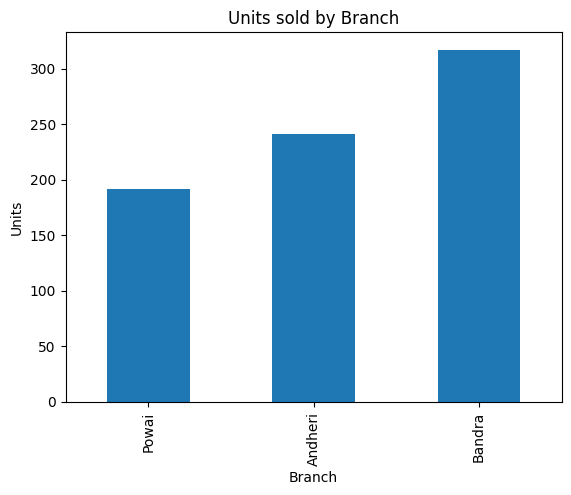

In [ ]:
item_qty = df.groupby('Branch')['Quantity'].sum().sort_values()

item_qty.plot(kind='bar')
plt.title('Units sold by Branch')
plt.xlabel("Branch")
plt.ylabel('Units')
plt.show()

In [ ]:
t = df.groupby('Branch')[['Quantity', 'Revenue']].sum()
t['Revenue_per_unit'] = t['Revenue'] / t['Quantity']
t

,Quantity,Revenue,Revenue_per_unit
Branch,,,
Andheri,241.0,10400.0,43.153527
Bandra,317.0,16400.0,51.735016
Powai,192.0,10415.0,54.244792


now i am going to Make a barh
 chart of revenue by item

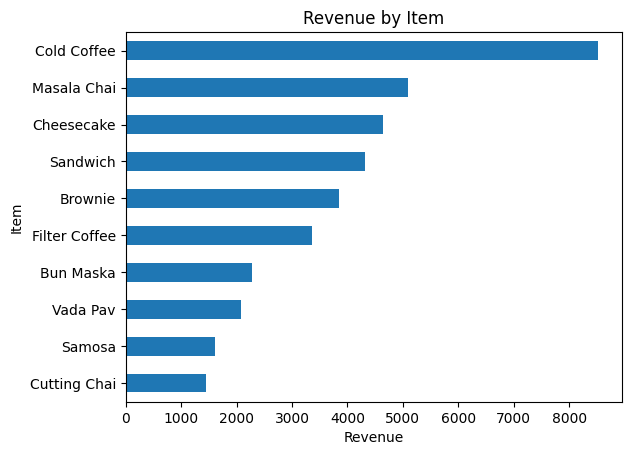

In [ ]:
item_rev = df.groupby('Item')['Revenue'].sum().sort_values()
item_rev.plot(kind='barh')
plt.title('Revenue by Item')
plt.xlabel('Revenue')
plt.ylabel('Item')
plt.show()

now i am going to make barh chart for item by quantity

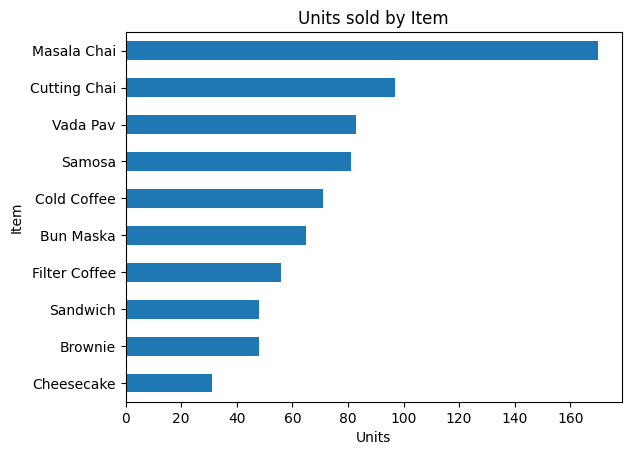

In [ ]:
item_qty = df.groupby('Item')['Quantity'].sum().sort_values()

item_qty.plot(kind='barh')
plt.title('Units sold by Item')
plt.ylabel("Item")
plt.xlabel('Units')
plt.show()

In [ ]:
p = df.groupby('Item')[['Quantity', 'Revenue']].sum()
p['Revenue_per_unit'] = p['Revenue'] / p['Quantity']
p


,Quantity,Revenue,Revenue_per_unit
Item,,,
Brownie,48.0,3840.0,80.0
Bun Maska,65.0,2275.0,35.0
Cheesecake,31.0,4650.0,150.0
Cold Coffee,71.0,8520.0,120.0
Cutting Chai,97.0,1455.0,15.0
Filter Coffee,56.0,3360.0,60.0
Masala Chai,170.0,5100.0,30.0
Samosa,81.0,1620.0,20.0
Sandwich,48.0,4320.0,90.0


now i am going to make a line chart of daily revenue

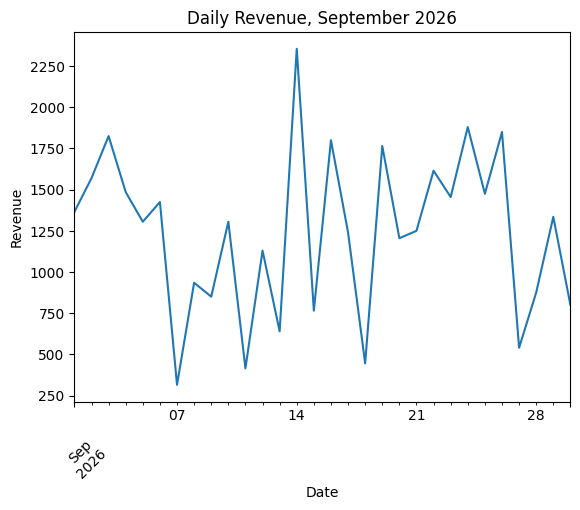

In [ ]:
daily = df.groupby('Order_Date')['Revenue'].sum()

daily.plot(kind='line')
plt.title('Daily Revenue, September 2026')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()


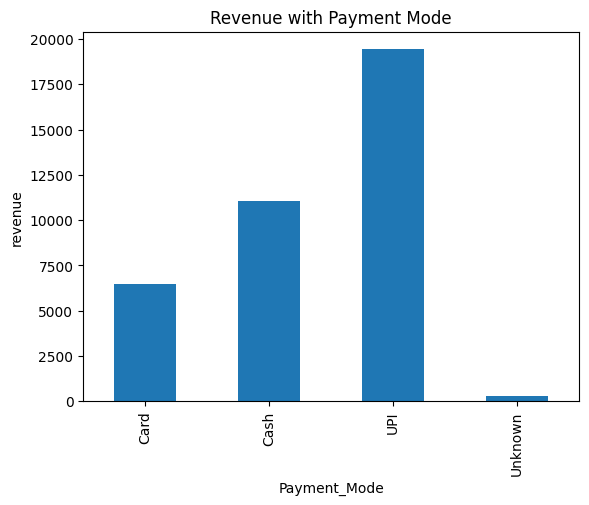

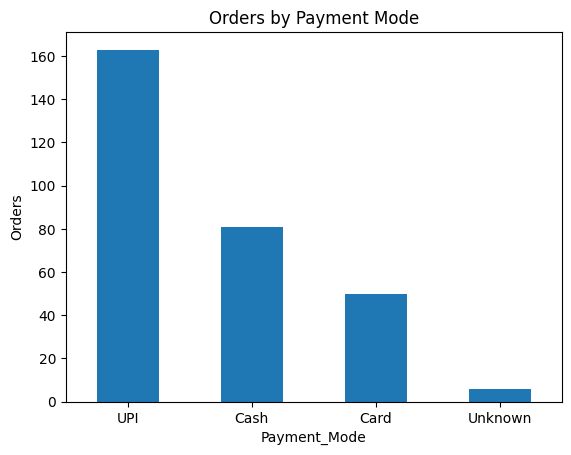

In [ ]:
PaymentM = df.groupby('Payment_Mode')['Revenue'].sum()
PaymentM.plot(kind="bar")
plt.title('Revenue with Payment Mode')
plt.xlabel('Payment_Mode')
plt.ylabel('revenue')
plt.show()



PaymentO = df['Payment_Mode'].value_counts()

PaymentO.plot(kind='bar')
plt.title('Orders by Payment Mode')
plt.xlabel('Payment_Mode')
plt.ylabel('Orders')
plt.xticks(rotation=0)
plt.show()


Table 1: average age by category, with the group sizes

In [ ]:
age_tbl = df.groupby('Category')['Customer_Age'].agg(['mean', 'count']).round(1)
age_tbl

,mean,count
Category,,
Beverage,38.8,160
Dessert,38.2,31
Snack,36.5,108


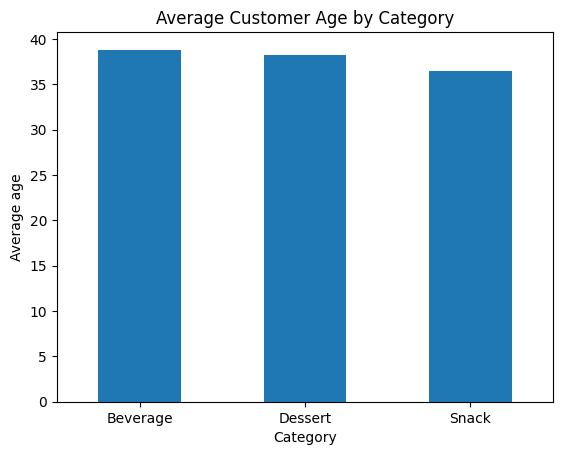

Table 2: average rating by branch, with the group sizes

In [ ]:
rating_tbl = df.groupby('Branch')['Rating'].agg(['mean', 'count']).round(2)
rating_tbl

,mean,count
Branch,,
Andheri,3.69,94
Bandra,3.64,118
Powai,3.57,70


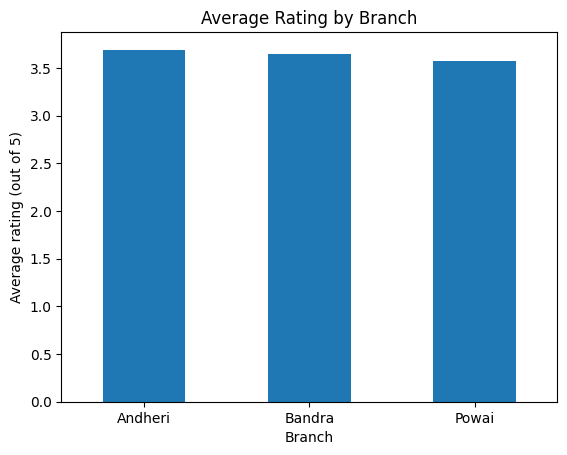

In [ ]:
rating_tbl['mean'].plot(kind='bar')
plt.title('Average Rating by Branch')
plt.xlabel('Branch')
plt.ylabel('Average rating (out of 5)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
orders = df['Payment_Mode'].value_counts()
units = df.groupby('Payment_Mode')['Quantity'].sum()


rev = df.groupby('Payment_Mode')['Revenue'].sum()


share = pd.DataFrame({'Orders_%': orders, 'Units_%': units, 'Revenue_%': rev}).round(1)
share

,Orders_%,Units_%,Revenue_%
Payment_Mode,,,
Card,50,129.0,6455.0
Cash,81,214.0,11065.0
UPI,163,396.0,19435.0
Unknown,6,11.0,260.0
